# Homework 2: K-Nearest Neighbors

Make sure you have these libraries installed. Run the cell below to check and install them if needed.

In [20]:
# Check and install required libraries
!pip install numpy matplotlib scikit-learn --quiet


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\aptls\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [21]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\aptls\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [22]:
# Basic imports used in several parts (you will need more imports later)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score

# Initial dataset for parts 1 and 2
X, y = make_blobs(n_samples=500, centers=2, n_features=2, random_state=6, cluster_std=2)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Part 1: K-Nearest Neighbors in Numpy

In [23]:
# Follow the HW instructions to make your own classifier in Numpy, evaluate its accuracy, and plot your results

# This function executes the core logic of KNN. Namely, it finds the k nearest
# neighbors to point, and then finds and returns the most common label among those k.
# Write a function that takes in a point, some data, and a parameter k,
# and returns the k closest points to the input
def predict_y(point, x_data, y_data, k):
  # Implement this function, using the tips below.
  # There are many acceptable ways of doing this, but a straightforward one
  # is using a sequence of optimization loops. This will be inefficient, but plenty
  # fast for our small datasets.

    labels = []

  # TODO: First, make copies of your input data so you don't modify them.
    x_cdata = np.copy(x_data)
    y_cdata = np.copy(y_data)
  # TODO: Next, find the closest value in x_data to point, and add its label (in y_data) to
  # the list labels. Then, remove these points from x_data and y_data.
    for _ in range(k):
        distance = np.linalg.norm(x_cdata - point, ord=2, axis = 1)
        closest_index = np.argmin(distance)
        labels.append(y_cdata[closest_index])

        x_cdata = np.delete(x_cdata, closest_index, axis = 0)
        y_cdata = np.delete(y_cdata, closest_index, axis = 0)
  # TODO: Repeat the above k times (using a loop)
    
  # Alternatively, there's another way of doing this that does not involve a loop
  # Feel free to implement it this way :)
    
  # TODO: Return the majority element in labels.
    most_common_label = max(set(labels), key = labels.count)
    
    return most_common_label

In [24]:
# TODO: Using your function above, predict the labels of all points in the testing data.
k_value = 3

y_predict = []

for test_input in X_test:
    prediction = predict_y(test_input, X_train, y_train, k_value)
    y_predict.append(prediction)
# TODO: Evaluate and print the accuracy of your classifier using the testing data (you will need to recall the definition of accuracy)
# (if your accuracy is below 0.9, you have probably made some sort of mistake)
y_predict = np.array(y_predict)

correct_predictions = np.sum(y_predict == y_test)
total_predictions = len(y_test)

accuracy = correct_predictions / total_predictions

print(f"Accuracy: {accuracy: .4f}")

Accuracy:  0.9000


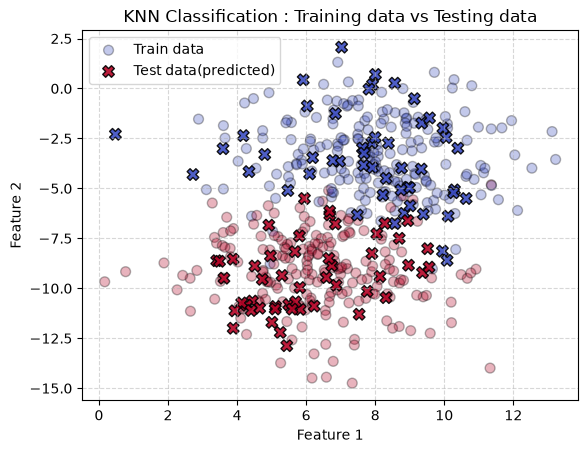

In [25]:
# TODO: Create a scatter plot to visualize your results. Make sure to follow the instructions in the assignment
# document, namely you should use point color to represent their predicted labels, and also alpha
# values to distinguish between training and test points.
plt.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap ='coolwarm', alpha = 0.3, edgecolor = 'k', s=50, label = 'Train data')
plt.scatter(X_test[:,0], X_test[:,1], c=y_predict, cmap ='coolwarm', alpha = 0.9, marker = 'X', edgecolor = 'k', s = 70, label = 'Test data(predicted)')

plt.title('KNN Classification : Training data vs Testing data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.show()

# Part 2: K-Nearest Neighbors in Sklearn

---



In [26]:
# Do the same analysis as part 1, but using KNeighborsClassifier from sklearn.neighbors
# Step 1. Build KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors = 3)

knn_model.fit(X_train,y_train)

y_pred_sklearn = knn_model.predict(X_test)


In [27]:
# Step 2. Calculate the Accuracy (>0.9)
accuracy = np.sum(y_pred_sklearn == y_test) / len(y_test)
print(f"Sklearn KNN Accuracy: {accuracy : .2f}")


Sklearn KNN Accuracy:  0.90


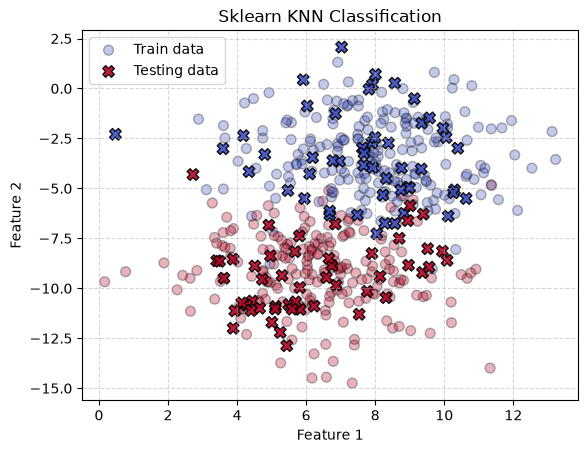

In [28]:
# Step 3. Plot
plt.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap = 'coolwarm', alpha = 0.3, edgecolor = 'k', s = 50, label = 'Train data')
plt.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', alpha = 0.9, marker = 'X', edgecolor = 'k', s = 70, label = 'Testing data')

plt.title('Sklearn KNN Classification')
plt.legend()
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.show()


# Part 3: Beyond a simple case
---

In real life, things are typically more complicated than the example we’ve been practicing with. For example, data can be messier, and you have to make several decisions about details of your algorithm. In this part, we will see several examples of this.




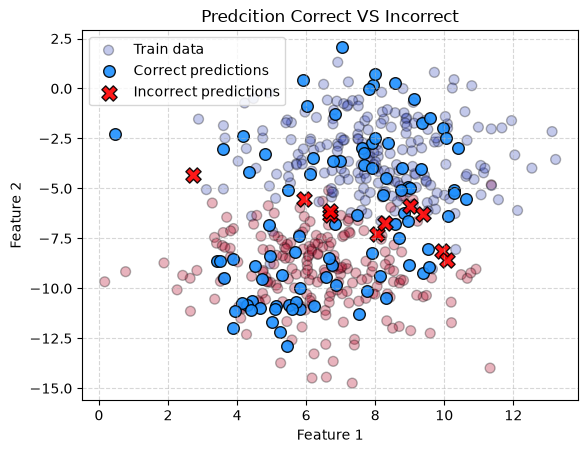

In [29]:
# In Parts 1 and 2, your final scatter plot displays the predicted labels for each test point.
# However, we cannot tell which predictions are correct and which are incorrect.
# Make another scatter plot displaying the prediction errors.
# That is, the color of each test point should depend on whether the prediction was correct or incorrect
# (make sure to also show the training points, as before).
# TODO: Plot the figure
correct = (y_test == y_pred_sklearn)
incorrect = (y_test != y_pred_sklearn)

plt.scatter(X_train[:,0], X_train[:,1], c = y_train, cmap ='coolwarm', alpha = 0.3, edgecolor = 'k', s = 50, label = 'Train data')
plt.scatter(X_test[correct,0], X_test[correct,1], color = 'dodgerblue', alpha = 0.9, marker = 'o', edgecolor = 'k', s = 70, label = 'Correct predictions')
plt.scatter(X_test[incorrect,0], X_test[incorrect,1], color = 'red', alpha = 0.9, marker = 'X', edgecolor = 'k', s = 120, label = 'Incorrect predictions')

plt.title('Predcition Correct VS Incorrect')
plt.legend(loc ='best')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.show()




K = 1 accuracy:  0.8800


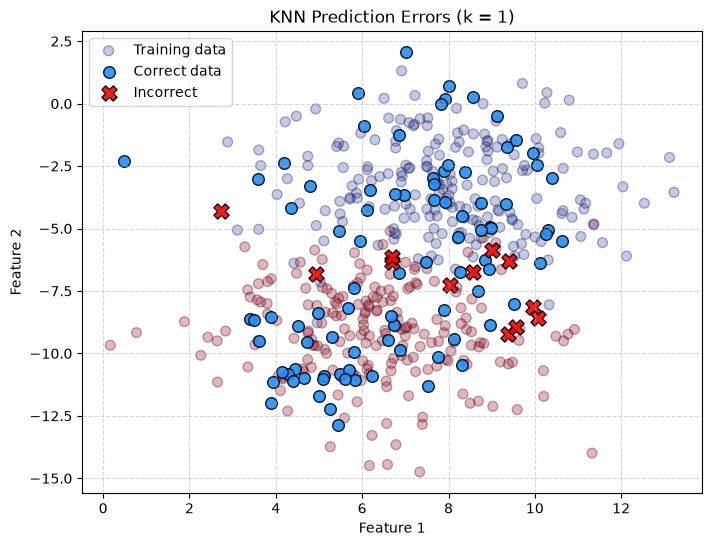

K = 3 accuracy:  0.9000


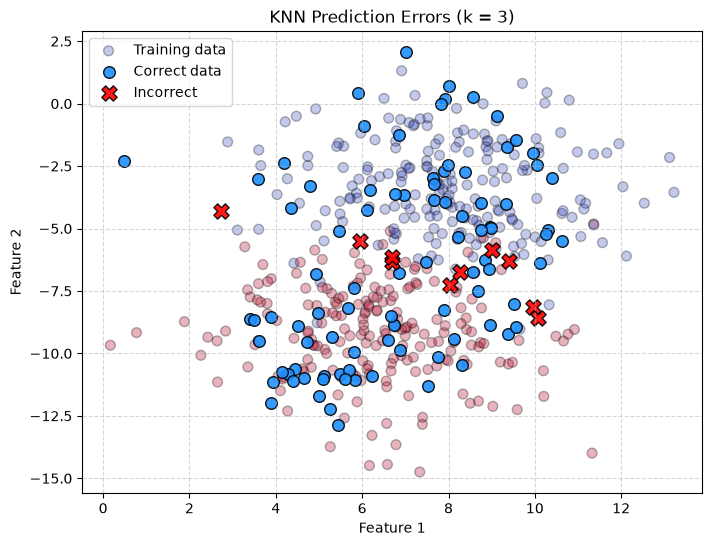

K = 5 accuracy:  0.8900


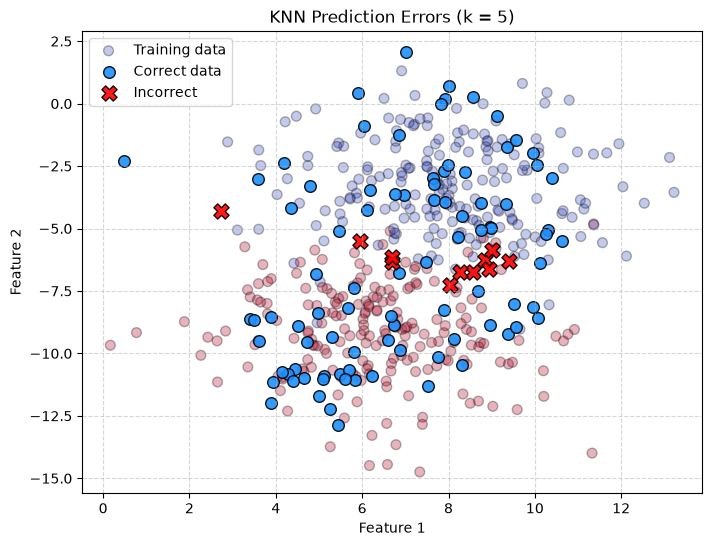

In [30]:
#Now, we will experiment with varying values of k (the main parameter of the model).
#Using the same data as above, train 3 KNN models with k=1,3, and 5.
# For each, display its accuracy, and show a scatter plot of prediction errors.
# Notice which particular points are correct/incorrect for which values of k, and how the accuracy changes.
# TODO: Experiment with different values of k (1,3, and 5) for the data above.
for k_values in [1,3,5]:
    y_pred_k = []
    for test_input in X_test:
        
        prediction = predict_y(test_input, X_train, y_train, k_values)
        y_pred_k.append(prediction)
        
    y_pred_k = np.array(y_pred_k)
    acc = np.sum(y_pred_k == y_test) / len(y_test)
    print(f"K = {k_values} accuracy: {acc: .4f}")

    correct = (y_test == y_pred_k)
    incorrect = (y_test != y_pred_k)
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train[:,0], X_train[:,1], c = y_train, cmap = 'coolwarm', alpha = 0.3, edgecolor = 'k', s = 50, label = 'Training data')
    plt.scatter(X_test[correct,0], X_test[correct,1], color = 'dodgerblue',  alpha = 0.9, marker = 'o', edgecolor = 'k', s = 70, label = 'Correct data')
    plt.scatter(X_test[incorrect,0], X_test[incorrect,1], color = 'red', alpha = 0.9, marker = 'X', edgecolor = 'k', s = 120, label = 'Incorrect')
        
    plt.title(f'KNN Prediction Errors (k = {k_values})')
    plt.xlabel("Feature 1")
    plt.ylabel('Feature 2')
    plt.grid(True, linestyle = '--', alpha = 0.5)
    plt.legend(loc = 'best')
    plt.show()



In [31]:
# Write a few sentences describing how and why the predictions change for different values of k,
# and justifying which choice of k you think seems best for this dataset.
# TODO: Write a few sentences justifying the best choice of k.


The predictions changed as the value of k increased. with the k = 1, the accuracy was 0.88, while k =3 was 0.90. When k was increased to 5,
the accuracy slightly decreased to 0.89. This happens because changing k changes how many neighboring points are used to determine the predicted
class. Based on these results k = 3 seems to be the best choice for this dataset. 

k = 1, accuracy =  0.815
k = 2, accuracy =  0.795
k = 3, accuracy =  0.840
k = 4, accuracy =  0.830
k = 5, accuracy =  0.835
k = 6, accuracy =  0.825
k = 7, accuracy =  0.830
k = 8, accuracy =  0.830
k = 9, accuracy =  0.835
k = 10, accuracy =  0.835
k = 11, accuracy =  0.845
k = 12, accuracy =  0.835
k = 13, accuracy =  0.840
k = 14, accuracy =  0.840
k = 15, accuracy =  0.845
k = 16, accuracy =  0.840
k = 17, accuracy =  0.845
k = 18, accuracy =  0.845
k = 19, accuracy =  0.845
k = 20, accuracy =  0.850
k = 21, accuracy =  0.845
k = 22, accuracy =  0.845
k = 23, accuracy =  0.845
k = 24, accuracy =  0.840
k = 25, accuracy =  0.830
k = 26, accuracy =  0.835
k = 27, accuracy =  0.825
k = 28, accuracy =  0.840
k = 29, accuracy =  0.825
k = 30, accuracy =  0.835

Best Model
Best k: 20
Best accuracy: 0.850


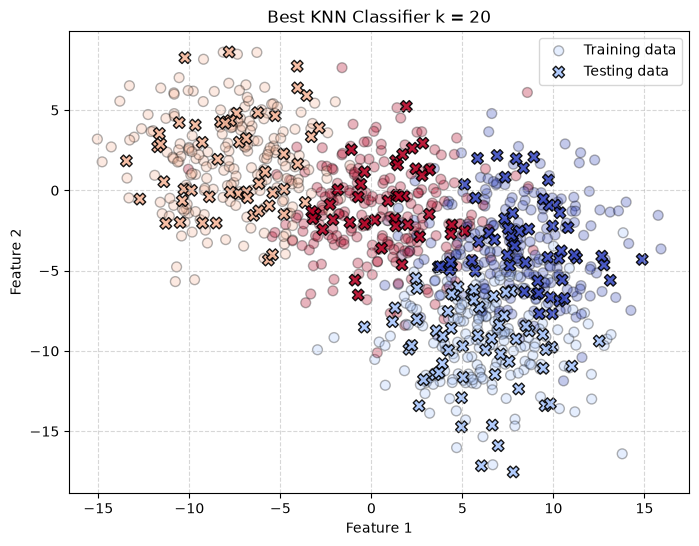

In [32]:
# Now, we will try a more complex example. Following the pattern above, train another KNN classifier (you may use sklearn) on the new provided dataset.
# Try several parameters to try to achieve the best accuracy possible
# (you can try various values of k, but also note that KNeighborsClassifier supports other options, which you may also experiment with).
# TODO: Try to train a good model for the following slightly more complicated dataset
X, y = make_blobs(n_samples=1000, centers=4, n_features=2, random_state=6, cluster_std=3)

X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

best_accuracy = 0
best_k = 0


for k in range(1,31):
    knn_model = KNeighborsClassifier(n_neighbors = k)
    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_test)
    accuracy = np.sum(y_pred == y_test)/len(y_test)
    print(f"k = {k}, accuracy = {accuracy: .3f}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k

print("\nBest Model")
print("Best k:", best_k)
print(f"Best accuracy: {best_accuracy:.3f}")

best_model = KNeighborsClassifier(n_neighbors = best_k)
best_model.fit(X_train, y_train)
best_y_pred = best_model.predict(X_test)

plt.figure(figsize = (8, 6))

plt.scatter(X_train[:,0], X_train[:,1], c = y_train, cmap = 'coolwarm', s = 50, alpha = 0.3, edgecolor = 'k', label = 'Training data')
plt.scatter(X_test[:,0], X_test[:,1], c = best_y_pred, cmap = 'coolwarm', alpha = 0.9, s = 70, marker = 'X', edgecolor = 'k', label = 'Testing data')

plt.title(f'Best KNN Classifier k = {best_k}')
plt.legend()
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.show()



Write a paragraph, with supporting code and plots, describing a good model for this dataset.

I tried to make the range of k value from 1 ~ 30, and for each k value, I wanted to have the best k value by comparing the accuracy.
As k increased around 20, the accuracy increased, but it decreased also as k is increased to 30. 
So, as we learned in class, increasing the k value is not always accurate for the best accuracy.

# Part 4: A real dataset

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
X shape: (150, 4)
y shape: (150,)


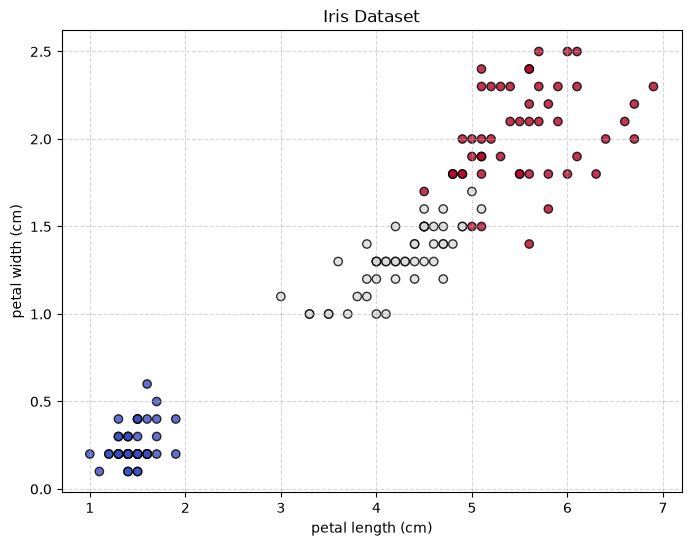

X_train shpae: (120, 4)
X_test shape: (30, 4)
k = 1, weights =uniform p = 1, CV accuracy = 0.950000
k = 1, weights =uniform p = 2, CV accuracy = 0.950000
k = 1, weights =distance p = 1, CV accuracy = 0.950000
k = 1, weights =distance p = 2, CV accuracy = 0.950000
k = 2, weights =uniform p = 1, CV accuracy = 0.925000
k = 2, weights =uniform p = 2, CV accuracy = 0.950000
k = 2, weights =distance p = 1, CV accuracy = 0.950000
k = 2, weights =distance p = 2, CV accuracy = 0.950000
k = 3, weights =uniform p = 1, CV accuracy = 0.958333
k = 3, weights =uniform p = 2, CV accuracy = 0.958333
k = 3, weights =distance p = 1, CV accuracy = 0.958333
k = 3, weights =distance p = 2, CV accuracy = 0.958333
k = 4, weights =uniform p = 1, CV accuracy = 0.950000
k = 4, weights =uniform p = 2, CV accuracy = 0.950000
k = 4, weights =distance p = 1, CV accuracy = 0.958333
k = 4, weights =distance p = 2, CV accuracy = 0.950000
k = 5, weights =uniform p = 1, CV accuracy = 0.941667
k = 5, weights =uniform p = 

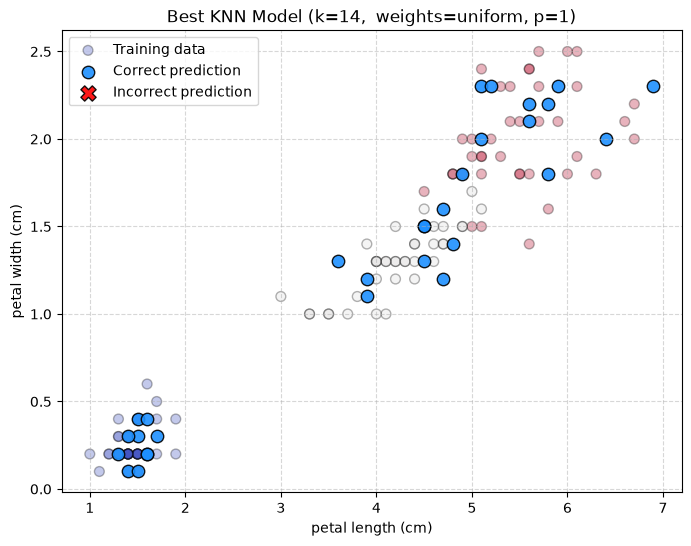

In [37]:
# TODO: try to train a *good* model for the following real world dataset.
# NOTE, this data is significantly messier than above. For example, the different features have very different ranges of values!
# We will talk more about this in class, but for now, try to find a reasonable classifier, you may also (optionally) normalize the feature values if you'd like to look more into that
data = load_iris()
X = data.data
y = data.target

print("Feature names:", data.feature_names)
print("Target names:", data.target_names)
print("X shape:", X.shape)
print("y shape:", y.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 2], X[:, 3], c=y, cmap='coolwarm', edgecolor='k', alpha=0.8)
plt.xlabel(data.feature_names[2])
plt.ylabel(data.feature_names[3])
plt.title('Iris Dataset')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shpae:", X_train.shape)
print("X_test shape:", X_test.shape)


best_accuracy = 0
best_k = 0
best_weights = ""
best_p = 0

for k in range(1,31):
    for weight_type in ['uniform','distance']:

        for p_val in [1, 2]:
            knn_model = KNeighborsClassifier( n_neighbors = k, weights = weight_type, p = p_val)

            scores = cross_val_score(knn_model, X_train, y_train, cv = 5, scoring = 'accuracy')
            mean_accuracy = np.mean(scores)
            print(f"k ={k:2d},"f" weights ={weight_type}", f"p = {p_val},", f"CV accuracy = {mean_accuracy:3f}")

            if mean_accuracy > best_accuracy:
                best_accuracy = mean_accuracy
                best_k = k
                best_weights = weight_type
                best_p = p_val

print("\nBest Model")
print("----------------------")
print(f"Best k: {best_k}")
print(f"Best weights: {best_weights}")
print(f"Best p: {best_p}")
print(f"Best CV accuracy: {best_accuracy:.3f}")

best_model = KNeighborsClassifier(n_neighbors = best_k, weights = best_weights, p = best_p)

best_model.fit(X_train, y_train)

best_y_pred = best_model.predict(X_test)

test_accuracy = np.sum(best_y_pred == y_test)/ len(y_test)

print(f"\nFinal Test accuracy:{test_accuracy: .3f}")

correct = (best_y_pred == y_test)
incorrect = (best_y_pred != y_test)

print("\nCorrect predictions:", np.sum(correct))
print("Incorrect predictions:", np.sum(incorrect))

plt.figure(figsize = (8, 6))

plt.scatter(X_train[:,2], X_train [:,3], c = y_train, cmap = 'coolwarm', edgecolor = 'k', alpha = 0.3, s = 50, label = 'Training data')
plt.scatter(X_test[correct, 2], X_test[correct, 3], marker = 'o', alpha = 0.9, color = 'dodgerblue', edgecolor = 'k', s= 80, label = 'Correct prediction')
plt.scatter(X_test[incorrect,2], X_test[incorrect, 3], marker = 'X', alpha = 0.9, color = 'red', edgecolor = 'k', s = 120, label = 'Incorrect prediction')

plt.xlabel(data.feature_names[2])
plt.ylabel(data.feature_names[3])

plt.title(f"Best KNN Model "f"(k={best_k}, "f" weights={best_weights}, "f"p={best_p})")
plt.legend(loc = 'best')
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.show()


#For this part, I got to know how many classes they have in the dataset by plotting the data and it has 3 different classes.
#Moreover, it has 4 features, and I used KNN to classify the iris data and tested different parameters to find a good model.
#In this code, I wanted to use the same method above, however, I got the best accuracy as k = 1, and the code was not working for for loop so that
#I decided to use 5 fold cross-validation for having better k value. So the highest average cross-validation accurcay was selected as the best.
#I tested k values from 1 to 30, uniform, distance, and p value of 1 and 2. 
#And then, I trained the best model using the full training set and tested it on the test set. I compared the
#predicted labels with the actual test labels to calculate the final accuracy.
# Just in case we cannot tell which one is correct, so I plotted the correct and incorrect predictions.

In [34]:
#For this part, I got to know how many classes they have in the dataset by plotting the data and it has 3 different classes.
#Moreover, it has 4 features, and I used KNN to classify the iris data and tested different parameters to find a good model.
#In this code, I wanted to use the same method above, however, I got the best accuracy as k = 1, and the code was not working for for loop so that
#I decided to use 5 fold cross-validation for having better k value. So the highest average cross-validation accurcay was selected as the best.
#I tested k values from 1 to 30, uniform, distance, and p value of 1 and 2. 
#And then, I trained the best model using the full training set and tested it on the test set. I compared the
#predicted labels with the actual test labels to calculate the final accuracy.
# Just in case we cannot tell which one is correct, so I plotted the correct and incorrect predictions.